# Session 4 — Classer des états de fonctionnement
**Master 2 – Diagnostic H2 · Université de La Réunion – ENERGY-Lab**
Étudiant : Nicolas NOYON

Classifieur KNN (k = 4, vote uniforme, distance euclidienne) qui distingue le fonctionnement nominal de la classe expérimentale « défaut pompe » à partir de six critères statistiques du courant d'un électrolyseur PEM.

Plan : A1 question physique · A2 KNN à la main · A3 chargement · A4 critères · A5 encodage · A6 apprentissage/prédiction · A7 matrices de confusion · A8 taux · A9 synthèse · A10 prolongement (optionnel).

## A1 — De la modification physique à la classe prédite

Dans un électrolyseur PEM, l'eau est amenée à l'anode, oxydée en O₂ et en protons ; les protons traversent la membrane et sont réduits à la cathode en H₂. Si un défaut de pompe modifie la circulation d'eau, l'hydratation de la membrane, la température ou le transport des gaz peuvent changer, et le **courant mesuré** peut en être affecté. C'est une **hypothèse** : les données ne disent ni quel circuit de pompe est en cause, ni la gravité du défaut, ni le mode de commande électrique.

Chaîne de traitement (chaque flèche est expliquée sous le schéma) :

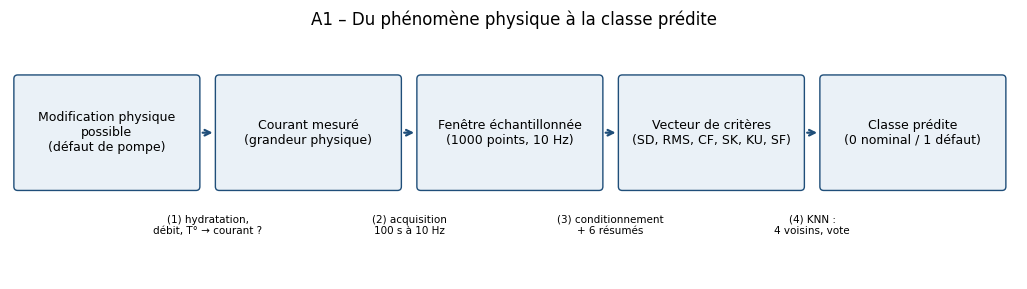

In [5]:
import numpy as np, scipy, scipy.io, sklearn
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(13, 3.2)); ax.axis("off"); ax.set_xlim(0, 13); ax.set_ylim(0, 3.2)
boites = ["Modification physique\npossible\n(défaut de pompe)", "Courant mesuré\n(grandeur physique)",
          "Fenêtre échantillonnée\n(1000 points, 10 Hz)", "Vecteur de critères\n(SD, RMS, CF, SK, KU, SF)", "Classe prédite\n(0 nominal / 1 défaut)"]
x0 = [0.1, 2.7, 5.3, 7.9, 10.5]
for x, t in zip(x0, boites):
    ax.add_patch(FancyBboxPatch((x, 1.2), 2.3, 1.4, boxstyle="round,pad=0.05", fc="#eaf1f7", ec="#1f4e79"))
    ax.text(x + 1.15, 1.9, t, ha="center", va="center", fontsize=9)
fleches = ["(1) hydratation,\ndébit, T° → courant ?", "(2) acquisition\n100 s à 10 Hz", "(3) conditionnement\n+ 6 résumés", "(4) KNN :\n4 voisins, vote"]
for i, t in enumerate(fleches):
    xa = x0[i] + 2.35; xb = x0[i+1] - 0.05
    ax.annotate("", xy=(xb, 1.9), xytext=(xa, 1.9), arrowprops=dict(arrowstyle="->", lw=1.6, color="#1f4e79"))
    ax.text((xa + xb) / 2, 0.7, t, ha="center", va="center", fontsize=7.5)
plt.title("A1 – Du phénomène physique à la classe prédite"); plt.show()

**Détail du code.** `plt.subplots` crée une figure vide ; chaque boîte est un rectangle arrondi (`FancyBboxPatch`) avec son texte, et `ax.annotate("", …, arrowprops=…)` trace une flèche entre deux boîtes. Aucun calcul : c'est uniquement le schéma demandé en A1 (5 boîtes, 4 flèches commentées).

**Explication des flèches.**
1. *Physique → courant* : c'est l'hypothèse à tester ; une modification de la circulation d'eau peut changer les conditions électrochimiques et donc le courant.
2. *Courant → fenêtre* : le courant est échantillonné (10 Hz pendant 100 s, 1000 valeurs) ; on passe d'une grandeur continue à une **représentation numérique**.
3. *Fenêtre → critères* : on garde 961 points puis on résume la fenêtre par six nombres (écart-type, RMS, facteur de crête/dégagement, skewness, kurtosis, facteur de forme).
4. *Critères → classe* : le KNN compare ce vecteur aux exemples étiquetés et vote. La **classe** est une étiquette humaine (0/1), distincte de la mesure et de sa représentation numérique.

**Deux informations expérimentales nécessaires pour tester le lien physique** : (i) *quel circuit de pompe est affecté et avec quelle gravité* (sévérité du défaut) ; (ii) *l'étalonnage du courant et le mode de commande* (courant imposé ou tension imposée), ainsi que l'indépendance des essais (identifiants de campagnes).

**ACP sans étiquettes.** L'ACP est non supervisée : elle décrit les directions de plus grande variance sans jamais utiliser les classes. Une composante principale ou un groupe ne correspond donc pas automatiquement à « défaut pompe » ; seules les étiquettes permettent d'associer une région de l'espace des critères à ce défaut.

## A2 — Exemple KNN en deux dimensions

In [6]:
import pandas as pd
x_new = np.array([0, 0])
V = np.array([[1, 0], [0, 2], [3, 0], [0, 4]]); lab = np.array([0, 1, 1, 0])
dist = np.sqrt(((V - x_new) ** 2).sum(axis=1))
tab = pd.DataFrame({"vecteur": [tuple(int(a) for a in v) for v in V], "classe": lab, "distance": dist}).sort_values("distance").reset_index(drop=True)
tab.index = tab.index + 1; tab.index.name = "rang"
display(tab)
for k in (3, 4):
    voisins = tab.iloc[:k]
    votes = voisins["classe"].value_counts().reindex([0, 1], fill_value=0)
    print(f"k={k} : voisins {[str(v) for v in voisins['vecteur']]}, votes classe 0 = {votes[0]}, classe 1 = {votes[1]}")

,vecteur,classe,distance
rang,,,
1,"(1, 0)",0,1.0
2,"(0, 2)",1,2.0
3,"(3, 0)",1,3.0
4,"(0, 4)",0,4.0


k=3 : voisins ['(1, 0)', '(0, 2)', '(3, 0)'], votes classe 0 = 1, classe 1 = 2
k=4 : voisins ['(1, 0)', '(0, 2)', '(3, 0)', '(0, 4)'], votes classe 0 = 2, classe 1 = 2


**Détail du code.**
- `dist = np.sqrt(((V - x_new)**2).sum(axis=1))` : distance euclidienne entre (0,0) et chaque vecteur d'apprentissage (différence, carré, somme sur les 2 coordonnées, racine).
- `sort_values("distance")` : classement du plus proche au plus loin → rang 1 à 4.
- La boucle `for k in (3, 4)` garde les k premiers voisins et compte leurs classes avec `value_counts`.

**Résultat.** Distances 1, 2, 3, 4. k = 3 → votes 1 (classe 0) contre 2 (classe 1) → prédiction 1. k = 4 → égalité 2–2 : le vote seul ne suffit pas.

**Résultat.** Distances : 1, 2, 3, 4. Pour **k = 3**, les voisins sont (1,0) [classe 0], (0,2) [classe 1], (3,0) [classe 1] : 1 voix pour la classe 0, 2 voix pour la classe 1 → **prédiction = classe 1**.
Pour **k = 4**, on ajoute (0,4) [classe 0] : 2 voix contre 2. **Le vote seul ne suffit pas** : il y a égalité, il faut une règle de départage (dans scikit-learn, la classe de plus petit indice, ici 0, est retenue). La *sélection des voisins* (tri par distance, on garde les k premiers) est donc distincte du *vote* (comptage des étiquettes).

## A3 — Chargement et inspection des données

In [7]:
print("numpy", np.__version__, "| scipy", scipy.__version__, "| scikit-learn", sklearn.__version__)
dossier = Path("/content") if Path("/content").exists() else Path(".")
Fichier_EA = scipy.io.loadmat(dossier / "PEM_Entrees_Apprentissage.mat")
Fichier_SA = scipy.io.loadmat(dossier / "PEM_Sorties_Apprentissage.mat")
Fichier_EV = scipy.io.loadmat(dossier / "PEM_Entrees_Validation.mat")
Fichier_SV = scipy.io.loadmat(dossier / "PEM_Sorties_Validation.mat")
for nom, F in [("EA", Fichier_EA), ("SA", Fichier_SA), ("EV", Fichier_EV), ("SV", Fichier_SV)]:
    print(nom, type(F).__name__, [k for k in F.keys() if not k.startswith("__")])

Data_EA = Fichier_EA["Entrees_signal_apprentissage"]
Data_SA = Fichier_SA["Sorties_apprentissage_EPEM"]
Data_EV = Fichier_EV["Entrees_signal_validation"]
Data_SV = Fichier_SV["Sorties_validation_EPEM"]

import pandas as pd
insp = pd.DataFrame({
    "tableau": ["Data_EA", "Data_SA", "Data_EV", "Data_SV"],
    "type": [type(a).__name__ for a in (Data_EA, Data_SA, Data_EV, Data_SV)],
    "dtype": [str(a.dtype) for a in (Data_EA, Data_SA, Data_EV, Data_SV)],
    "forme": [a.shape for a in (Data_EA, Data_SA, Data_EV, Data_SV)],
    "rôle": ["entrées d'apprentissage (courant)", "classes d'apprentissage", "entrées de validation (courant)", "classes de validation"]})
display(insp)

numpy 2.1.3 | scipy 1.16.3 | scikit-learn 1.6.1
EA dict ['Entrees_signal_apprentissage']
SA dict ['Sorties_apprentissage_EPEM']
EV dict ['Entrees_signal_validation']
SV dict ['Sorties_validation_EPEM']


,tableau,type,dtype,forme,rôle
0,Data_EA,ndarray,float64,"(384, 1000)",entrées d'apprentissage (courant)
1,Data_SA,ndarray,object,"(384, 1)",classes d'apprentissage
2,Data_EV,ndarray,float64,"(96, 1000)",entrées de validation (courant)
3,Data_SV,ndarray,object,"(96, 1)",classes de validation


**Détail du code.**
- `scipy.io.loadmat` lit un fichier `.mat` et renvoie un dictionnaire (`dict`) ; on affiche ses clés (hors clés techniques `__header__`…) pour vérifier les noms.
- On extrait ensuite chaque tableau avec sa clé : `Data_EA` (entrées d'apprentissage), `Data_SA` (classes d'apprentissage), `Data_EV` et `Data_SV` (idem pour la validation).
- Le tableau `insp` résume type, dtype, forme et rôle.

**Résultat.** `Data_EA` (384, 1000) et `Data_EV` (96, 1000) sont des matrices de réels (`float64`) : une ligne = un exemple de 1000 points. `Data_SA` (384, 1) et `Data_SV` (96, 1) sont de type `object` : ce sont des textes (les noms des classes), pas des nombres. Les versions des bibliothèques sont affichées pour la reproductibilité.

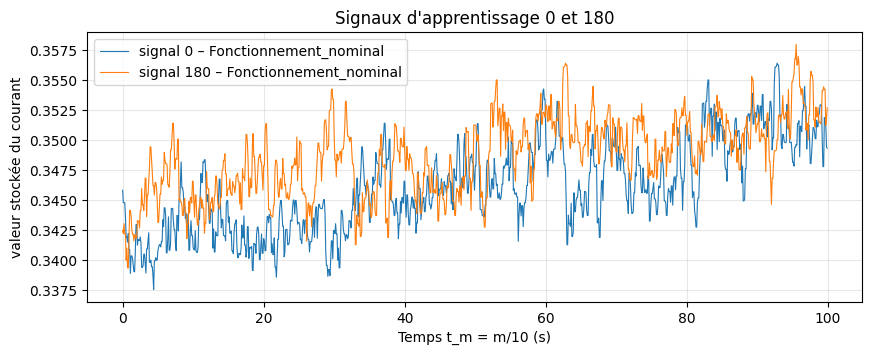

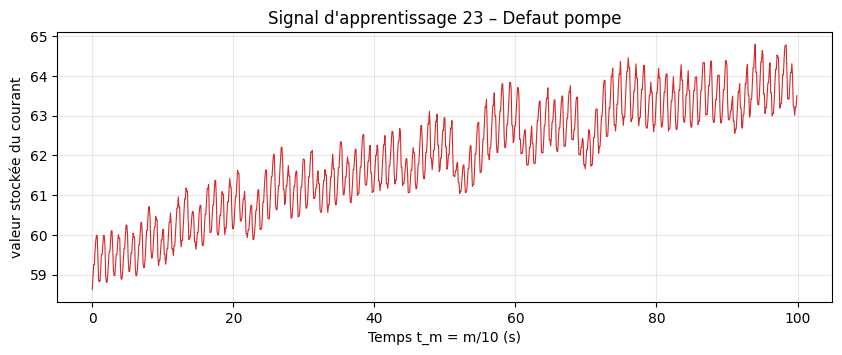

Classes : {0: 'Fonctionnement_nominal', 180: 'Fonctionnement_nominal', 23: 'Defaut pompe'}


In [8]:
fs = 10.0
t = np.arange(Data_EA.shape[1]) / fs        # t_m = m / 10, en secondes
etiq = lambda D, i: str(D[i, 0][0])

plt.figure(figsize=(10, 3.5))
for i in (0, 180):
    plt.plot(t, Data_EA[i], lw=0.8, label=f"signal {i} – {etiq(Data_SA, i)}")
plt.xlabel("Temps t_m = m/10 (s)"); plt.ylabel("valeur stockée du courant")
plt.title("Signaux d'apprentissage 0 et 180"); plt.legend(); plt.grid(alpha=.3); plt.show()

plt.figure(figsize=(10, 3.5))
plt.plot(t, Data_EA[23], lw=0.8, color="C3")
plt.xlabel("Temps t_m = m/10 (s)"); plt.ylabel("valeur stockée du courant")
plt.title(f"Signal d'apprentissage 23 – {etiq(Data_SA, 23)}"); plt.grid(alpha=.3); plt.show()
print("Classes :", {i: etiq(Data_SA, i) for i in (0, 180, 23)})

**Détail du code.** `t = np.arange(1000)/10` construit l'axe du temps $t_m = m/10$ en secondes (de 0 à 99,9 s). `Data_EA[i]` est la ligne *i*, c'est-à-dire un signal complet. `etiq(Data_SA, i)` lit la classe de la **même** ligne *i* ; c'est ce qui garantit que signal et étiquette restent associés. Deux figures : signaux 0 et 180 ensemble, puis signal 23 seul.

**Résultat.** Les signaux 0 et 180 sont nominaux, le signal 23 est en défaut pompe. Les trois courbes sont du même ordre de grandeur et ont une allure de courant oscillant : à l'œil, la classe n'est pas évidente, d'où l'intérêt de résumer chaque signal par des critères.

**Lecture.** Chaque ligne de `Data_EA`/`Data_EV` est un exemple (1000 points, 100 s à 10 Hz) ; la ligne *i* est associée à l'étiquette d'indice *i* de `Data_SA`/`Data_SV`. L'étalonnage du courant n'étant pas documenté, l'axe vertical indique « valeur stockée du courant ».

## A4 — Extraction des critères (conventions de la session 2)
Conditionnement : on garde les $M=N^2$ premiers points, $N=\lfloor\sqrt{L}\rfloor$ (961 sur 1000 ; dernier instant 96,0 s). CF = facteur de dégagement (*clearance factor*), KU = kurtosis sans soustraction de 3.

In [9]:
def conditionnement(s):
    """Conserve les M = N^2 premiers points, N = floor(sqrt(L))."""
    s = np.asarray(s, dtype=float).ravel()
    N = int(np.floor(np.sqrt(len(s))))
    return s[:N * N]

def calcul_criteres_statistiques(s):
    """Retourne [SD, RMS, CF, SK, KU, SF] pour un signal conditionné."""
    s = np.asarray(s, dtype=float)
    m = s.mean()
    sd  = np.sqrt(np.mean((s - m) ** 2))
    rms = np.sqrt(np.mean(s ** 2))
    a   = np.abs(s)
    cf  = a.max() / np.mean(np.sqrt(a)) ** 2        # clearance factor
    sk  = np.mean((s - m) ** 3) / sd ** 3
    ku  = np.mean((s - m) ** 4) / sd ** 4            # kurtosis sans -3
    sf  = rms / np.mean(a)
    return [sd, rms, cf, sk, ku, sf]

print("Points conservés :", len(conditionnement(Data_EA[0])), "| supprimés :", Data_EA.shape[1] - len(conditionnement(Data_EA[0])))
X_train = np.array([calcul_criteres_statistiques(conditionnement(r)) for r in Data_EA])
X_test  = np.array([calcul_criteres_statistiques(conditionnement(r)) for r in Data_EV])
noms = ["SD", "RMS", "CF", "SK", "KU", "SF"]
print("X_train :", X_train.shape, "| X_test :", X_test.shape)
print("Colonnes :", noms)
print("Valeurs finies  X_train :", np.isfinite(X_train).all(), "| X_test :", np.isfinite(X_test).all())
display(pd.DataFrame({"min": X_train.min(0), "max": X_train.max(0)}, index=noms).round(4))
assert X_train.shape == (384, 6) and X_test.shape == (96, 6) and np.isfinite(X_train).all() and np.isfinite(X_test).all()

Points conservés : 961 | supprimés : 39
X_train : (384, 6) | X_test : (96, 6)
Colonnes : ['SD', 'RMS', 'CF', 'SK', 'KU', 'SF']
Valeurs finies  X_train : True | X_test : True


,min,max
SD,0.0027,2.9558
RMS,0.3291,79.6024
CF,1.0009,1.0731
SK,-0.7351,0.7014
KU,1.7022,3.4430
SF,1.0000,1.0008


**Détail du code.**
- `conditionnement` : calcule $N=\lfloor\sqrt{L}\rfloor$ (31 pour L = 1000) et garde les $M=N^2=961$ premiers points ; 39 sont supprimés. Les trois autres opérations (`ravel`, `float`) assurent un vecteur 1D de réels.
- `calcul_criteres_statistiques` applique les formules de l'énoncé, dans l'ordre SD, RMS, CF, SK, KU, SF : écart-type, valeur efficace, facteur de dégagement (crête divisée par $(\text{moyenne de }\sqrt{|s|})^2$), skewness (asymétrie), kurtosis (aplatissement, sans −3) et facteur de forme (RMS / moyenne de $|s|$).
- Les deux compréhensions de liste appliquent « conditionnement puis critères » à chaque ligne de `Data_EA` et `Data_EV` ; `np.array` donne `X_train` et `X_test`.
- `np.isfinite(...).all()` vérifie qu'aucune valeur n'est NaN ou infinie ; l'`assert` arrête le notebook sinon.

**Résultat.** 961 points conservés, `X_train` (384, 6), `X_test` (96, 6), toutes les valeurs finies. Le tableau min/max montre des échelles très différentes : RMS va de 0,33 à 79,6 alors que CF, SF restent entre 1,00 et 1,07. Ce point est repris en A10.

Chaque ligne est une expérience ; la colonne *j* désigne le même critère dans les deux jeux. Toutes les valeurs sont finies : aucune valeur indéfinie (ex. SD = 0) n'est apparue, donc aucun remplacement par zéro n'a été nécessaire.

## A5 — Encodage des classes

In [10]:
print("Exemple de cellule :", repr(Data_SA[0, 0]), "->", repr(str(Data_SA[0, 0][0])))
CODES = {"Fonctionnement_nominal": 0, "Defaut pompe": 1}

def encoder(D):
    out = []
    for i in range(D.shape[0]):
        lab = str(D[i, 0][0])
        if lab not in CODES:
            raise ValueError(f"Étiquette inconnue à l'indice {i} : {lab!r}")
        out.append(CODES[lab])
    return np.array(out, dtype=int)

Y_train = encoder(Data_SA); Y_test = encoder(Data_SV)
for nom, Y in (("Y_train", Y_train), ("Y_test", Y_test)):
    print(nom, "| forme", Y.shape, "| dtype", Y.dtype, "| effectifs [0,1] =", np.bincount(Y))
print("Classe apprentissage ligne 0 :", Y_train[0], "| ligne 23 :", Y_train[23])
assert Y_train.shape == (384,) and Y_test.shape == (96,) and list(np.bincount(Y_train)) == [288, 96] and list(np.bincount(Y_test)) == [72, 24]

Exemple de cellule : array(['Fonctionnement_nominal'], dtype='<U22') -> 'Fonctionnement_nominal'
Y_train | forme (384,) | dtype int64 | effectifs [0,1] = [288  96]
Y_test | forme (96,) | dtype int64 | effectifs [0,1] = [72 24]
Classe apprentissage ligne 0 : 0 | ligne 23 : 1


**Détail du code.**
- Le dictionnaire `CODES` fixe l'encodage imposé : `Fonctionnement_nominal` → 0, `Defaut pompe` → 1.
- `encoder` parcourt chaque ligne, extrait la chaîne (`D[i,0][0]`, car chaque cellule est elle-même un petit tableau de texte) et la convertit. Une étiquette inconnue déclenche une erreur au lieu d'être rangée dans une classe arbitraire.
- `np.bincount` compte les effectifs ; l'`assert` vérifie formes (384,), (96,) et effectifs 288/96 et 72/24.

**Résultat.** `Y_train` et `Y_test` sont des vecteurs d'entiers à une dimension, avec les effectifs attendus (75 % de nominaux dans les deux jeux). La ligne 0 est de classe 0 et la ligne 23 de classe 1, ce qui confirme les figures d'A3.

**Rôle des tableaux.** `X_train` + `Y_train` servent à **apprendre** (`fit`). `X_test` sert à **prédire** (`predict`) sans voir ses étiquettes ; `Y_test` n'est utilisé qu'ensuite pour **évaluer** ces prédictions. La séparation fournie est conservée. Les fichiers ne donnent pas d'identifiants d'essais : on ne peut pas affirmer que les campagnes d'acquisition sont indépendantes, la conclusion porte donc sur le jeu de validation fourni.

## A6 — Apprentissage du KNN et prédiction

In [11]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

model = KNeighborsClassifier(n_neighbors=4, weights="uniform", metric="minkowski", p=2)
print(model.get_params())
model.fit(X_train, Y_train)
Y_train_KNN = model.predict(X_train)
Y_test_KNN  = model.predict(X_test)
print("Formes :", Y_train_KNN.shape, Y_test_KNN.shape)
print(f"Proportion correcte – apprentissage : {accuracy_score(Y_train, Y_train_KNN):.3f}")
print(f"Proportion correcte – validation    : {accuracy_score(Y_test,  Y_test_KNN):.3f}")

{'algorithm': 'auto', 'leaf_size': 30, 'metric': 'minkowski', 'metric_params': None, 'n_jobs': None, 'n_neighbors': 4, 'p': 2, 'weights': 'uniform'}
Formes : (384,) (96,)
Proportion correcte – apprentissage : 0.966
Proportion correcte – validation    : 0.917


**Détail du code.**
- `KNeighborsClassifier(n_neighbors=4, weights="uniform", metric="minkowski", p=2)` : 4 voisins, chaque voisin compte une voix, distance de Minkowski d'ordre 2 = euclidienne. `get_params()` affiche cette configuration.
- `model.fit(X_train, Y_train)` : mémorise les 384 vecteurs et leurs classes (le KNN n'« apprend » pas de paramètres).
- `model.predict(...)` : pour chaque ligne, cherche les 4 plus proches voisins dans l'apprentissage et renvoie la classe majoritaire. `Y_test` n'est **pas** donné à `predict`.
- `accuracy_score` = proportion de prédictions égales aux vraies classes.

**Résultat.** Prédictions de formes (384,) et (96,). Proportion correcte : **0,966** en apprentissage, **0,917** en validation. Le score d'apprentissage est optimiste (les exemples sont déjà connus du modèle) ; celui de validation est le test réel.

La proportion d'apprentissage est mesurée sur des exemples **déjà vus** par `fit` (chacun est son propre plus proche voisin, à distance 0) : elle est optimiste. Seul le score de validation teste le classifieur fixé sur des exemples absents de son apprentissage.

**Détail d'un vote** (exemple de validation mal classé, voir A7) :

In [12]:
erreurs = np.where(Y_test_KNN != Y_test)[0]
i_err = int(erreurs[0])
dist, idx = model.kneighbors(X_test[i_err].reshape(1, -1))
voisins = pd.DataFrame({"voisin (indice apprentissage)": idx[0], "distance": dist[0].round(4), "classe": Y_train[idx[0]]})
voisins.index += 1
display(voisins)
votes = np.bincount(Y_train[idx[0]], minlength=2)
print(f"Exemple de validation {i_err} : classe réelle = {Y_test[i_err]}, votes [nominal, défaut] = {votes}, prédite = {Y_test_KNN[i_err]}")
print("Ex-aequo (2–2) sur la validation :", int((np.array([np.bincount(Y_train[j], minlength=2) for j in model.kneighbors(X_test, return_distance=False)])[:,0] == 2).sum()))

,voisin (indice apprentissage),distance,classe
1,311,0.0729,1
2,323,0.0795,1
3,380,0.0836,0
4,299,0.1191,1


Exemple de validation 8 : classe réelle = 0, votes [nominal, défaut] = [1 3], prédite = 1
Ex-aequo (2–2) sur la validation : 0


**Détail du code.**
- `np.where(Y_test_KNN != Y_test)` liste les indices mal classés ; on prend le premier (`i_err`).
- `model.kneighbors(X_test[i_err])` renvoie les distances et les indices des 4 voisins dans l'apprentissage ; on affiche leurs classes.
- `np.bincount(classes des voisins)` fait le vote : [nombre de nominaux, nombre de défauts].
- La dernière ligne compte les exemples de validation avec une égalité 2–2.

**Résultat.** Exemple 8 : voisins 311, 323, 380, 299 à des distances de 0,073 à 0,119, de classes 1, 1, 0, 1. Votes [1, 3] → prédiction 1 (défaut) alors que la classe réelle est 0 : c'est une fausse alarme. Aucune égalité 2–2 n'apparaît sur la validation, donc la règle de départage n'a pas influencé les résultats.

**Explication.** Le KNN calcule la distance euclidienne entre le vecteur de critères de l'exemple et ceux des 384 exemples d'apprentissage, retient les 4 plus proches, compte leurs étiquettes (vote uniforme) et prédit la classe majoritaire. Ici, 3 des 4 voisins appartiennent à la classe « défaut pompe » : la prédiction est donc 1 alors que la classe réelle est 0. Les paramètres de référence restent fixés pendant toute la validation.

## A7 — Matrices de confusion

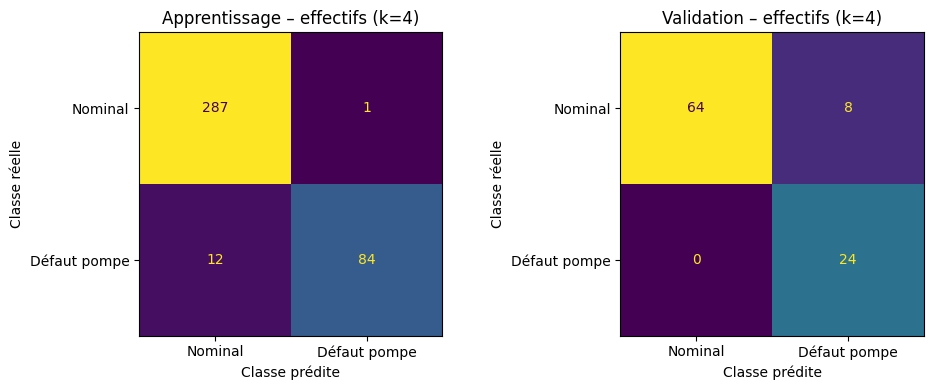

Apprentissage: TN=287 FP=1 FN=12 TP=84 | total=384 | sommes des lignes=[288  96] | effectifs réels=[288  96]
Validation: TN=64 FP=8 FN=0 TP=24 | total=96 | sommes des lignes=[72 24] | effectifs réels=[72 24]


In [13]:
C_train = confusion_matrix(Y_train, Y_train_KNN, labels=[0, 1])
C_test  = confusion_matrix(Y_test,  Y_test_KNN,  labels=[0, 1])
fig, axs = plt.subplots(1, 2, figsize=(10, 4))
for ax, C, titre in zip(axs, (C_train, C_test), ("Apprentissage", "Validation")):
    ConfusionMatrixDisplay(C, display_labels=["Nominal", "Défaut pompe"]).plot(ax=ax, colorbar=False)
    ax.set_title(f"{titre} – effectifs (k=4)"); ax.set_xlabel("Classe prédite"); ax.set_ylabel("Classe réelle")
plt.tight_layout(); plt.show()
for nom, C, Y in (("Apprentissage", C_train, Y_train), ("Validation", C_test, Y_test)):
    TN, FP, FN, TP = C.ravel()
    print(f"{nom}: TN={TN} FP={FP} FN={FN} TP={TP} | total={C.sum()} | sommes des lignes={C.sum(1)} | effectifs réels={np.bincount(Y)}")
    assert (C.sum(1) == np.bincount(Y)).all()

**Détail du code.** `confusion_matrix(Y_reel, Y_predit, labels=[0, 1])` compte, pour chaque couple (classe réelle, classe prédite), le nombre d'exemples ; l'ordre [0, 1] place les lignes = réel et les colonnes = prédit. `ConfusionMatrixDisplay` dessine la matrice avec des axes nommés. `C.ravel()` donne TN, FP, FN, TP, et l'`assert` vérifie que chaque somme de ligne égale l'effectif réel de la classe.

**Résultat.**
- Apprentissage : TN = 287, FP = 1, FN = 12, TP = 84.
- Validation : TN = 64, FP = 8, FN = 0, TP = 24.

Les sommes de lignes valent 288/96 et 72/24, comme attendu. En validation, tous les défauts sont détectés mais 8 nominaux sont pris pour des défauts.

**Lecture.** Lignes = classe réelle, colonnes = classe prédite, ordre [0, 1], défaut pompe = classe positive : $C=\begin{pmatrix}TN&FP\\FN&TP\end{pmatrix}$. Une **fausse alarme** (FP, $C_{01}$) est un exemple nominal classé en défaut ; un **défaut manqué** (FN, $C_{10}$) est un défaut classé nominal. Les sommes des lignes (288/96 et 72/24) retrouvent bien les effectifs réels.

En validation : 8 fausses alarmes, 0 défaut manqué.

### Analyse d'une erreur de validation

Indice de validation : 8
Classe réelle : 0 (nominal) | classe prédite : 1 (défaut pompe)
Classes des 4 voisins : [1, 1, 0, 1] | indices apprentissage : [311, 323, 380, 299]


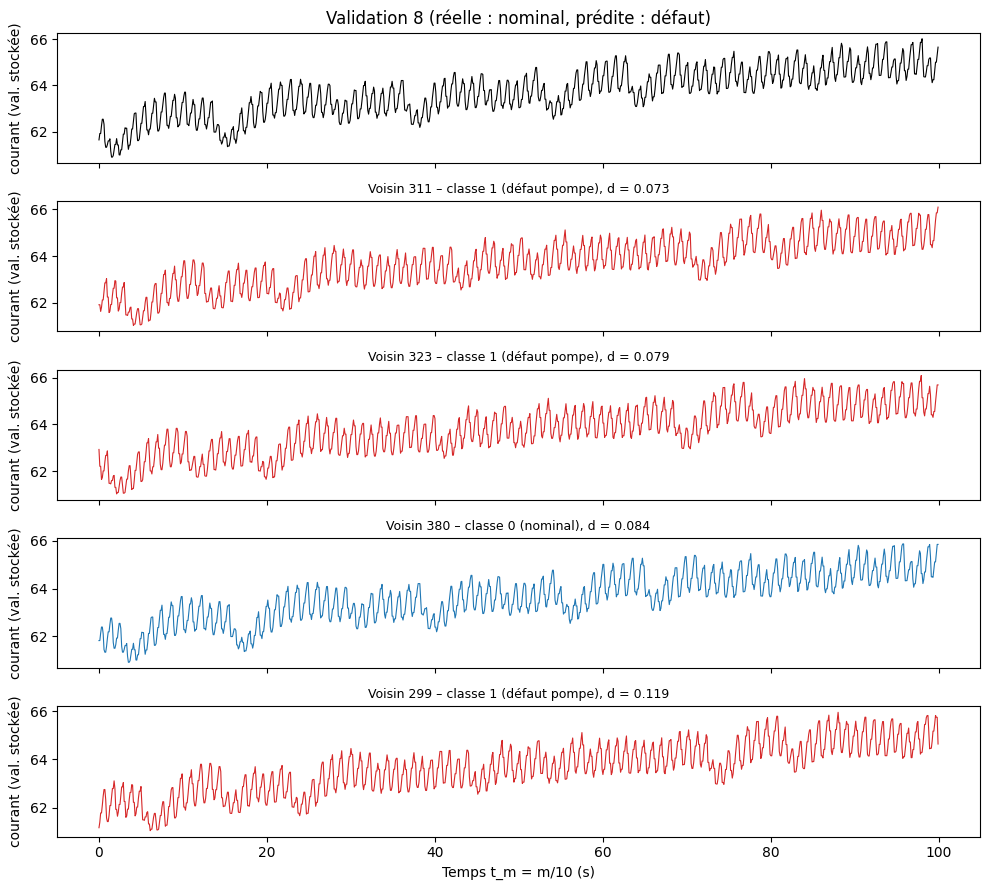

Indices de toutes les erreurs de validation : [8, 20, 32, 44, 56, 68, 80, 92]


In [14]:
print(f"Indice de validation : {i_err}")
print(f"Classe réelle : {Y_test[i_err]} (nominal) | classe prédite : {Y_test_KNN[i_err]} (défaut pompe)")
print(f"Classes des 4 voisins : {Y_train[idx[0]].tolist()} | indices apprentissage : {idx[0].tolist()}")
fig, axs = plt.subplots(5, 1, figsize=(10, 9), sharex=True)
axs[0].plot(t, Data_EV[i_err], color="k", lw=.8); axs[0].set_title(f"Validation {i_err} (réelle : nominal, prédite : défaut)")
for a, j in zip(axs[1:], idx[0]):
    a.plot(t, Data_EA[j], lw=.8, color="C3" if Y_train[j] else "C0")
    a.set_title(f"Voisin {j} – classe {Y_train[j]} ({'défaut pompe' if Y_train[j] else 'nominal'}), d = {dist[0][list(idx[0]).index(j)]:.3f}", fontsize=9)
axs[-1].set_xlabel("Temps t_m = m/10 (s)")
for a in axs: a.set_ylabel("courant (val. stockée)")
plt.tight_layout(); plt.show()
print("Indices de toutes les erreurs de validation :", erreurs.tolist())

**Détail du code.** On reprend l'exemple 8 : le premier tracé (noir) est son signal de validation ; les 4 tracés suivants sont ses voisins d'apprentissage (rouge = défaut, bleu = nominal) avec leur distance. La dernière ligne liste toutes les erreurs de validation.

**Résultat.** Le signal 8 ressemble beaucoup à ses voisins (même tendance croissante, mêmes oscillations), y compris au voisin nominal 380 : à l'œil, rien ne distingue clairement un nominal d'un défaut ici. Les 8 erreurs sont aux indices 8, 20, 32, 44, 56, 68, 80, 92, espacés de 12 : elles forment un motif régulier, ce qui suggère des fenêtres liées à une même séquence d'acquisition (à vérifier avec les identifiants d'essais, absents des fichiers).

**Fiche de l'erreur.** Indice de validation 8 ; classe réelle : nominal ; classe prédite : défaut pompe (fausse alarme) ; 3 voisins sur 4 sont en défaut.

**Hypothèse à vérifier (non démontrée).** Cette fenêtre nominale a un vecteur de critères proche d'exemples « défaut » : elle pourrait correspondre à un fonctionnement nominal proche du défaut (transitoire, niveau de courant ou conditions voisines). Il faudrait pour le confirmer : les conditions d'acquisition de cette fenêtre (courant imposé, température, débit d'eau), l'étalonnage du courant, et savoir si cette fenêtre provient du même essai que les voisins en défaut. L'erreur observée est un fait ; sa cause physique reste une hypothèse.

## A8 — Taux par classe, taux global, normalisation

,r0 – nominaux reconnus (%),r1 – rappel défaut (%),a – taux global (%)
Apprentissage,99.65,87.5,96.61
Validation,88.89,100.0,91.67


Référence « toujours nominal » : 75.0 % (validation) | 75.0 % (apprentissage)


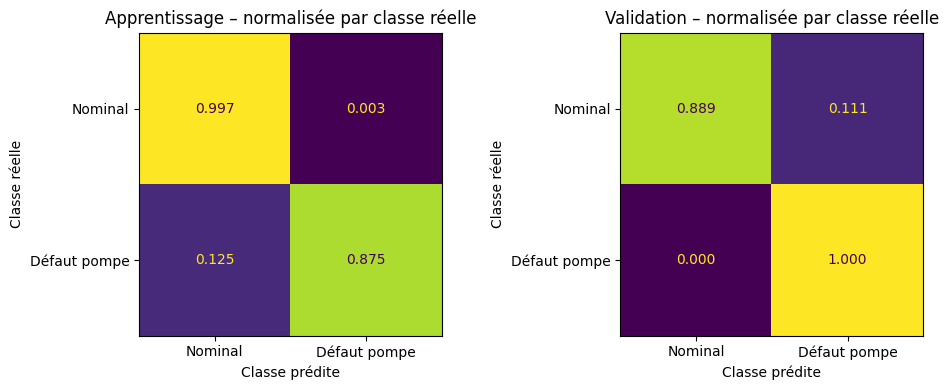

Apprentissage: diagonale normalisée = [0.9965 0.875 ] | r0, r1 calculés = 0.9965, 0.875
Validation: diagonale normalisée = [0.8889 1.    ] | r0, r1 calculés = 0.8889, 1.0


In [15]:
def taux(C):
    TN, FP, FN, TP = C.ravel()
    return 100 * TN / (TN + FP), 100 * TP / (TP + FN), 100 * (TN + TP) / C.sum()
tab = pd.DataFrame([taux(C_train), taux(C_test)], index=["Apprentissage", "Validation"],
                   columns=["r0 – nominaux reconnus (%)", "r1 – rappel défaut (%)", "a – taux global (%)"]).round(2)
display(tab)
print("Référence « toujours nominal » :", 100 * np.mean(Y_test == 0), "% (validation) |", 100 * np.mean(Y_train == 0), "% (apprentissage)")

fig, axs = plt.subplots(1, 2, figsize=(10, 4))
for ax, Y, P, titre in zip(axs, (Y_train, Y_test), (Y_train_KNN, Y_test_KNN), ("Apprentissage", "Validation")):
    ConfusionMatrixDisplay.from_predictions(Y, P, labels=[0, 1], display_labels=["Nominal", "Défaut pompe"],
                                            normalize="true", values_format=".3f", ax=ax, colorbar=False)
    ax.set_title(f"{titre} – normalisée par classe réelle"); ax.set_xlabel("Classe prédite"); ax.set_ylabel("Classe réelle")
plt.tight_layout(); plt.show()
for nom, C, Y, P in (("Apprentissage", C_train, Y_train, Y_train_KNN), ("Validation", C_test, Y_test, Y_test_KNN)):
    Cn = confusion_matrix(Y, P, labels=[0, 1], normalize="true")
    r0, r1, _ = taux(C)
    print(f"{nom}: diagonale normalisée = {np.diag(Cn).round(4)} | r0, r1 calculés = {round(r0/100,4)}, {round(r1/100,4)}")
    assert np.allclose(np.diag(Cn), [r0/100, r1/100])

**Détail du code.**
- `taux(C)` applique les formules : $r_0=TN/(TN+FP)$, $r_1=TP/(TP+FN)$, $a=(TN+TP)/\text{total}$, ×100.
- `normalize="true"` divise chaque ligne par son total (proportions prédites au sein de chaque classe réelle).
- La boucle finale compare la diagonale normalisée à $r_0$ et $r_1$ calculés à la main ; l'`assert` échoue si elles diffèrent.

**Résultat.** Validation : $r_0$ = 88,89 %, $r_1$ = 100 %, $a$ = 91,67 %. Apprentissage : 99,65 %, 87,50 %, 96,61 %. La référence « toujours nominal » donne 75 %. Les diagonales normalisées (0,8889 et 1,0 en validation) coïncident avec les taux calculés : les deux méthodes sont cohérentes.

**Les trois taux répondent à des questions différentes.** $r_0$ (spécificité) : parmi les exemples nominaux, quelle proportion est laissée tranquille ? $r_1$ (rappel) : parmi les défauts, quelle proportion est détectée ? $a$ : parmi tous les exemples, quelle proportion est bien classée ? La diagonale des matrices normalisées par ligne redonne exactement $r_0$ et $r_1$ ; $a$ exige les deux effectifs de classe.

**Résultats (validation).** $r_0 = 88{,}89\,\%$ (8 fausses alarmes sur 72), $r_1 = 100\,\%$ (aucun défaut manqué sur 24), $a = 91{,}67\,\%$. Un classifieur « toujours nominal » obtiendrait 75 % de taux global en ne reconnaissant aucun défaut : le taux global seul ne décrit donc pas la performance diagnostique, d'où l'intérêt des taux par classe. Ici le KNN fait mieux que cette référence (+16,7 points) et détecte tous les défauts de validation, au prix de fausses alarmes (11,1 % des nominaux). En apprentissage, le profil est inverse ($r_0 = 99{,}65\,\%$, $r_1 = 87{,}50\,\%$, $a = 96{,}61\,\%$) mais ces chiffres portent sur des exemples déjà vus.

**Fausses alarmes vs défauts manqués.** Une fausse alarme peut provoquer une intervention inutile ; un défaut manqué peut laisser persister un fonctionnement anormal. Leur poids relatif dépend de l'application (coût d'un arrêt, risque pour la membrane, sécurité).

**Conclusion et portée.** Ces données montrent que, sur le jeu de validation fourni, six critères statistiques du courant et un KNN (k = 4) séparent nettement la classe « défaut pompe » du fonctionnement nominal (aucun défaut manqué, 8 fausses alarmes). Elles ne montrent pas la cause physique, ni la généralisation à de nouveaux essais : seulement 24 défauts, indépendance des campagnes non documentée. Pour un transfert vers un autre système il faudrait : le circuit de pompe et la gravité du défaut, l'étalonnage du courant et le mode de commande, des essais indépendants (identifiants de campagnes) et un jeu de test jamais utilisé pour choisir le modèle.

## A9 — Synthèse et auto-évaluation

1. **L'ACP utilise-t-elle les classes cibles ?** Non. L'ACP est non supervisée : elle cherche les directions de variance maximale à partir des seuls vecteurs de critères. Une composante principale n'identifie donc pas à elle seule un défaut.
2. **$k$ désigne-t-il le nombre de classes ?** Non. $k$ est le nombre de voisins qui participent au vote (ici 4) ; le jeu contient deux classes quelle que soit la valeur de $k$.
3. **`fit` reçoit-il `Y_test` ?** Non. `fit` reçoit uniquement `X_train` et `Y_train`. `Y_test` ne sert qu'à évaluer les prédictions de `X_test`, sinon le test ne serait pas indépendant de l'apprentissage.
4. **CF est-il le facteur de crête ?** Non (c'était l'erreur à corriger après échange). Dans cette session, CF désigne le *facteur de dégagement* (clearance factor) : $\max|s|/(M^{-1}\sum\sqrt{|s|})^2$, et non le facteur de crête $\max|s|/RMS$.
5. **Que compte $C_{01}$ ?** La ligne 0 est la classe réelle « nominal », la colonne 1 la classe prédite « défaut » : $C_{01}$ = FP, nombre de fausses alarmes (nominaux classés en défaut). Ici 8 en validation.
6. **Reconnaître les 24 défauts de validation garantit-il la reconnaissance des défauts futurs ?** Non. Le résultat vaut pour le jeu fourni (24 défauts seulement, conditions et indépendance des essais non documentées) ; un défaut de gravité, de circuit ou de condition différents peut ne pas être reconnu.

**Vérification finale.** Le notebook a été exécuté de haut en bas après redémarrage du noyau ; les matrices de confusion sont expliquées en A7 et A8 (les relectures croisées par un binôme ne peuvent pas être consignées ici).

## A10 (optionnel) — Influence du nombre de voisins, de la métrique et de l'échelle des critères

**Règle de protocole.** Les candidats sont comparés **uniquement sur les données d'apprentissage**, par validation croisée interne (5 blocs contigus, sans mélange, car des fenêtres voisines peuvent provenir du même essai). Le jeu de validation n'est utilisé qu'**une seule fois**, pour la configuration retenue.

### Échelles des critères

In [16]:
display(pd.DataFrame({"min": X_train.min(0), "max": X_train.max(0), "écart-type": X_train.std(0)}, index=noms).round(4))

,min,max,écart-type
SD,0.0027,2.9558,0.6700
RMS,0.3291,79.6024,27.4277
CF,1.0009,1.0731,0.0173
SK,-0.7351,0.7014,0.2574
KU,1.7022,3.4430,0.3916
SF,1.0000,1.0008,0.0001


**Détail du code.** Tableau des minimum, maximum et écart-type de chaque colonne de `X_train`, pour comparer les échelles. **Résultat.** RMS a un écart-type d'environ 27 contre 0,0001 pour SF : dans une distance euclidienne, RMS et SD domineraient, les autres critères comptant presque pour rien.

Les critères n'ont pas la même échelle (RMS atteint ≈ 80 alors que CF, SF restent proches de 1). Sans standardisation, la distance est dominée par SD et RMS : SK, KU, CF et SF pèsent très peu dans la décision.

In [17]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

cv = StratifiedKFold(n_splits=5, shuffle=False)          # blocs contigus
lignes = []
for scale in (False, True):
    for metrique in ("euclidean", "manhattan"):
        for k in (1, 3, 4, 5, 7, 9, 15):
            knn = KNeighborsClassifier(n_neighbors=k, weights="uniform", metric=metrique)
            est = make_pipeline(StandardScaler(), knn) if scale else knn   # scaler ajusté dans chaque bloc d'apprentissage
            r = cross_validate(est, X_train, Y_train, cv=cv, scoring=["accuracy", "balanced_accuracy", "recall"])
            lignes.append(dict(standardisation=scale, métrique=metrique, k=k,
                               accuracy_cv=r["test_accuracy"].mean(), accuracy_équilibrée_cv=r["test_balanced_accuracy"].mean(),
                               rappel_défaut_cv=r["test_recall"].mean()))
res = pd.DataFrame(lignes).sort_values("accuracy_équilibrée_cv", ascending=False).reset_index(drop=True)
display(res.head(10).round(3))
best = res.iloc[0]; print("Configuration retenue (validation croisée, apprentissage seul) :", dict(best[["standardisation", "métrique", "k"]]))

,standardisation,métrique,k,accuracy_cv,accuracy_équilibrée_cv,rappel_défaut_cv
0,True,euclidean,1,0.922,0.903,0.864
1,True,manhattan,1,0.914,0.890,0.843
2,True,euclidean,3,0.917,0.889,0.833
3,False,manhattan,15,0.898,0.865,0.800
4,True,manhattan,3,0.896,0.865,0.802
5,True,euclidean,5,0.896,0.864,0.802
6,True,euclidean,4,0.906,0.861,0.771
7,False,euclidean,15,0.896,0.860,0.789
8,True,manhattan,15,0.885,0.857,0.800
9,True,euclidean,15,0.880,0.853,0.800


Configuration retenue (validation croisée, apprentissage seul) : {'standardisation': np.True_, 'métrique': 'euclidean', 'k': np.int64(1)}


**Détail du code.**
- `StratifiedKFold(n_splits=5, shuffle=False)` coupe l'apprentissage en 5 blocs contigus en gardant les proportions de classes ; sans mélange, des fenêtres voisines (probablement du même essai) restent dans le même bloc.
- Les trois boucles testent k ∈ {1, 3, 4, 5, 7, 9, 15}, distance euclidienne ou Manhattan, avec ou sans standardisation (14 combinaisons par option de standardisation, 28 au total).
- `make_pipeline(StandardScaler(), knn)` ajuste la standardisation **dans chaque bloc d'apprentissage seulement** : aucune information du bloc de test ne fuit.
- `cross_validate` renvoie accuracy, accuracy équilibrée (moyenne de $r_0$ et $r_1$, adaptée à des classes déséquilibrées) et rappel défaut ; on classe selon l'accuracy équilibrée.

**Résultat.** Meilleure configuration : standardisation, distance euclidienne, k = 1 (accuracy équilibrée ≈ 0,90, accuracy ≈ 0,92). La référence k = 4 standardisée est un peu plus basse (≈ 0,86). Le jeu de validation n'a pas servi à ce choix.

In [18]:
knn_f = KNeighborsClassifier(n_neighbors=int(best["k"]), weights="uniform", metric=best["métrique"])
final = make_pipeline(StandardScaler(), knn_f) if best["standardisation"] else knn_f
final.fit(X_train, Y_train)
P_f = final.predict(X_test)                     # une seule évaluation sur la validation fournie
C_f = confusion_matrix(Y_test, P_f, labels=[0, 1])
cmp_ = pd.DataFrame([taux(C_test), taux(C_f)], index=["Référence (k=4, euclid., sans standardisation)", "Configuration retenue"],
                    columns=["r0 (%)", "r1 (%)", "a (%)"]).round(2)
display(cmp_); print("Matrice de confusion finale :\n", C_f)

,r0 (%),r1 (%),a (%)
"Référence (k=4, euclid., sans standardisation)",88.89,100.0,91.67
Configuration retenue,88.89,100.0,91.67


Matrice de confusion finale :
 [[64  8]
 [ 0 24]]


**Détail du code.** On construit le modèle avec la configuration retenue, on l'apprend sur **tout** l'apprentissage, puis on prédit **une seule fois** `X_test`. On compare ses taux à ceux de la référence.

**Résultat.** Taux identiques à la référence (88,89 % / 100 % / 91,67 %) et même matrice de confusion [[64, 8], [0, 24]] : les mêmes 8 fausses alarmes subsistent. Changer k, la métrique ou l'échelle n'apporte donc rien de mesurable sur ce jeu de validation.

**Lecture.** Le choix des paramètres (k, métrique, standardisation) n'a utilisé que les données d'apprentissage ; le jeu de validation n'est évalué qu'une fois, avec la configuration figée. La comparaison avec la référence est donc un bilan final honnête pour *ce* choix. Si l'on retouchait les paramètres après avoir regardé les résultats de validation, ce jeu ne serait plus une évaluation indépendante.

**Résultat.** La configuration retenue par validation croisée (standardisation, distance euclidienne, k = 1) donne exactement les mêmes taux de validation que la référence (88,89 % / 100 % / 91,67 %) : dans ce jeu, le changement de paramètres n'améliore pas la validation, et l'écart de validation croisée (≈ 0,92 contre ≈ 0,91 pour k = 4 standardisé) est faible. Les 8 fausses alarmes subsistent.

**Hypothèse d'indépendance.** Sans identifiants d'essais, on suppose que les fenêtres d'apprentissage et de validation proviennent de campagnes indépendantes, et que les blocs de validation croisée ne partagent pas d'essai. Rien dans les fichiers ne le garantit : des fenêtres issues du même essai, présentes des deux côtés, rendraient les scores trop optimistes.